# Лабораторная работа №1. Метод обратного распространения ошибки

Костанян А. К.

Импорт библиотек и параметры обучения.

In [ ]:
from pathlib import Path
from time import perf_counter
import gzip
import struct
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits

SEED = 42
HIDDEN_SIZE = 300
LEARNING_RATE = 0.1
BATCH_SIZE = 64
EPOCHS = 20

blas_limit = threadpool_limits(limits=1, user_api="blas")
np.set_printoptions(precision=4, suppress=True)

## 1. Данные MNIST

Загружаем данные, нормируем пиксели и показываем примеры.

In [ ]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"


def load_idx(filename):
    path = DATA_DIR / filename
    if not path.exists():
        print("Загрузка:", filename)
        temporary_path = path.with_suffix(".part")
        urllib.request.urlretrieve(BASE_URL + filename, temporary_path)
        temporary_path.replace(path)

    with gzip.open(path, "rb") as file:
        zero, data_type, dimensions = struct.unpack(">HBB", file.read(4))
        if zero != 0 or data_type != 8 or dimensions not in (1, 3):
            raise ValueError(f"Неверный заголовок IDX: {filename}")
        shape = struct.unpack(">" + "I" * dimensions, file.read(4 * dimensions))
        values = np.frombuffer(file.read(), dtype=np.uint8)
    return values.reshape(shape)


train_images = load_idx("train-images-idx3-ubyte.gz")
y_train = load_idx("train-labels-idx1-ubyte.gz").astype(np.int64)
test_images = load_idx("t10k-images-idx3-ubyte.gz")
y_test = load_idx("t10k-labels-idx1-ubyte.gz").astype(np.int64)

assert train_images.shape == (60000, 28, 28)
assert test_images.shape == (10000, 28, 28)
assert y_train.shape == (60000,) and y_test.shape == (10000,)
assert np.all((y_train >= 0) & (y_train <= 9))
assert np.all((y_test >= 0) & (y_test <= 9))

X_train = train_images.reshape(-1, 784).astype(np.float32) / 255.0
X_test = test_images.reshape(-1, 784).astype(np.float32) / 255.0

print("Обучающие изображения:", train_images.shape)
print("Тестовые изображения:", test_images.shape)
print("Одно изображение:", train_images[0].shape)
print("Метки:", y_train.shape, y_test.shape, "форма одной метки:", y_train[0].shape)
print("Входы сети:", X_train.shape, X_test.shape, "тип:", X_train.dtype)
print("Диапазон входов:", X_train.min(), X_train.max())

Обучающие изображения: (60000, 28, 28)
Тестовые изображения: (10000, 28, 28)
Одно изображение: (28, 28)
Метки: (60000,) (10000,) форма одной метки: ()
Входы сети: (60000, 784) (10000, 784) тип: float32
Диапазон входов: 0.0 1.0


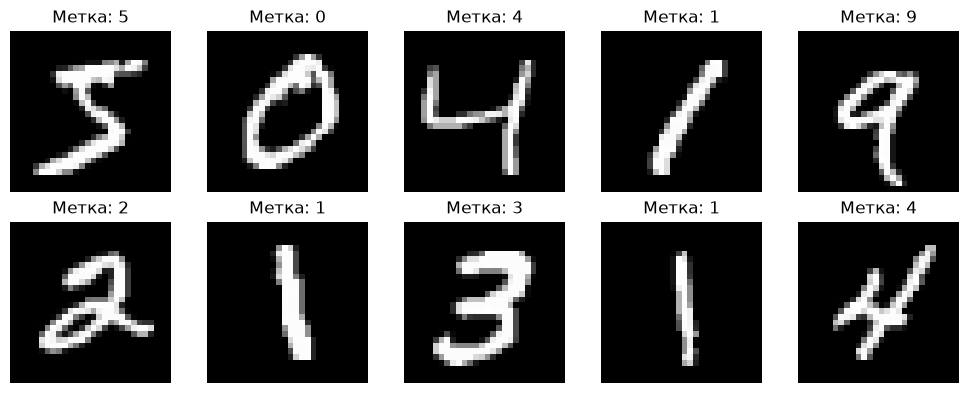

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_images[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Метка: {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Прямой проход

Создаём веса, вычисляем вероятности классов и кросс-энтропию.

In [4]:
def initialize_parameters(input_size, hidden_size, output_size, rng):
    return {
        "W1": (rng.standard_normal((input_size, hidden_size))
               * np.sqrt(2.0 / input_size)).astype(np.float32),
        "b1": np.zeros(hidden_size, dtype=np.float32),
        "W2": (rng.standard_normal((hidden_size, output_size))
               * np.sqrt(1.0 / hidden_size)).astype(np.float32),
        "b2": np.zeros(output_size, dtype=np.float32),
    }


def forward(X, parameters):
    Z1 = X @ parameters["W1"] + parameters["b1"]
    A1 = np.maximum(0, Z1)
    Z2 = A1 @ parameters["W2"] + parameters["b2"]
    shifted = Z2 - Z2.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    P = exp_scores / exp_scores.sum(axis=1, keepdims=True)
    # Z1 и A1 сохраняем для обратного прохода.
    return Z1, A1, shifted, P


def cross_entropy(shifted, y):
    rows = np.arange(len(y))
    log_normalizer = np.log(np.exp(shifted).sum(axis=1))
    return np.mean(log_normalizer - shifted[rows, y])

## 3. Обратный проход

Вычисляем градиенты весов и смещений.

In [5]:
def backward(X, y, parameters, Z1, A1, P):
    m = len(y)
    D2 = P.copy()
    D2[np.arange(m), y] -= 1
    D2 /= m

    dW2 = A1.T @ D2
    db2 = D2.sum(axis=0)
    D1 = (D2 @ parameters["W2"].T) * (Z1 > 0)
    dW1 = X.T @ D1
    db1 = D1.sum(axis=0)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

## 4. Проверка градиентов

Сравниваем градиенты с численными производными на маленькой сети.

In [ ]:
def check_gradients():
    rng = np.random.default_rng(123)
    X = rng.normal(size=(4, 3))
    y = np.array([0, 1, 0, 1])
    parameters = initialize_parameters(3, 5, 2, rng)
    parameters = {name: value.astype(np.float64) for name, value in parameters.items()}
    Z1, A1, shifted, P = forward(X, parameters)
    epsilon = 1e-5
    assert np.min(np.abs(Z1)) > epsilon * max(1.0, np.max(np.abs(X)))
    analytical = backward(X, y, parameters, Z1, A1, P)

    for name, values in parameters.items():
        numerical = np.zeros_like(values)
        for index in np.ndindex(values.shape):
            original = values[index]
            values[index] = original + epsilon
            loss_plus = cross_entropy(forward(X, parameters)[2], y)
            values[index] = original - epsilon
            loss_minus = cross_entropy(forward(X, parameters)[2], y)
            values[index] = original
            numerical[index] = (loss_plus - loss_minus) / (2 * epsilon)
        difference = np.max(np.abs(numerical - analytical[name]))
        print(f"{name}: максимальное абсолютное расхождение = {difference:.2e}")
        np.testing.assert_allclose(analytical[name], numerical, atol=1e-7, rtol=1e-5)
    print("Проверка градиентов пройдена")


check_gradients()

W1: максимальное абсолютное расхождение = 6.32e-12
b1: максимальное абсолютное расхождение = 3.65e-12
W2: максимальное абсолютное расхождение = 4.60e-12
b2: максимальное абсолютное расхождение = 6.85e-12
Проверка градиентов пройдена.


## 5. Обучение

Обучаем сеть 20 эпох, выводим ошибку train и время каждой эпохи.

In [7]:
def evaluate(X, y, parameters, batch_size=1024):
    total_loss = 0.0
    correct = 0
    for start in range(0, len(y), batch_size):
        X_batch = X[start:start + batch_size]
        y_batch = y[start:start + batch_size]
        _, _, shifted, P = forward(X_batch, parameters)
        total_loss += float(cross_entropy(shifted, y_batch)) * len(y_batch)
        correct += np.count_nonzero(P.argmax(axis=1) == y_batch)
    return total_loss / len(y), correct / len(y)


# Повторное выполнение ячейки начинает обучение заново с тех же весов.
rng = np.random.default_rng(SEED)
parameters = initialize_parameters(784, HIDDEN_SIZE, 10, rng)
history = {"loss": [], "error": [], "seconds": []}
training_start = perf_counter()

for epoch in range(1, EPOCHS + 1):
    epoch_start = perf_counter()
    order = rng.permutation(len(y_train))

    for start in range(0, len(order), BATCH_SIZE):
        indices = order[start:start + BATCH_SIZE]
        X_batch, y_batch = X_train[indices], y_train[indices]
        Z1, A1, _, P = forward(X_batch, parameters)
        gradients = backward(X_batch, y_batch, parameters, Z1, A1, P)
        for name in parameters:
            parameters[name] -= LEARNING_RATE * gradients[name]

    train_loss, train_accuracy = evaluate(X_train, y_train, parameters)
    seconds = perf_counter() - epoch_start
    history["loss"].append(train_loss)
    history["error"].append(1 - train_accuracy)
    history["seconds"].append(seconds)
    print(f"Эпоха {epoch:2d}/{EPOCHS}: loss = {train_loss:.4f}, "
          f"ошибка train = {100 * (1 - train_accuracy):.2f}%, "
          f"время = {seconds:.2f} с", flush=True)

training_seconds = perf_counter() - training_start
print(f"Обучение и оценки train: {training_seconds:.1f} с "
      f"({training_seconds / 60:.2f} мин)")

Эпоха  1/20: loss = 0.2230, ошибка train = 6.32%, время = 1.09 с
Эпоха  2/20: loss = 0.1559, ошибка train = 4.36%, время = 1.13 с
Эпоха  3/20: loss = 0.1235, ошибка train = 3.48%, время = 1.13 с
Эпоха  4/20: loss = 0.0981, ошибка train = 2.71%, время = 1.10 с
Эпоха  5/20: loss = 0.0823, ошибка train = 2.25%, время = 1.11 с
Эпоха  6/20: loss = 0.0722, ошибка train = 1.98%, время = 1.13 с
Эпоха  7/20: loss = 0.0621, ошибка train = 1.67%, время = 1.10 с
Эпоха  8/20: loss = 0.0534, ошибка train = 1.38%, время = 1.11 с
Эпоха  9/20: loss = 0.0465, ошибка train = 1.17%, время = 1.09 с
Эпоха 10/20: loss = 0.0422, ошибка train = 1.03%, время = 1.07 с
Эпоха 11/20: loss = 0.0388, ошибка train = 0.94%, время = 1.11 с
Эпоха 12/20: loss = 0.0366, ошибка train = 0.87%, время = 1.07 с
Эпоха 13/20: loss = 0.0317, ошибка train = 0.73%, время = 1.09 с
Эпоха 14/20: loss = 0.0274, ошибка train = 0.59%, время = 1.07 с
Эпоха 15/20: loss = 0.0247, ошибка train = 0.47%, время = 1.07 с
Эпоха 16/20: loss = 0.024

## 6. Оценка на тестовой выборке

Выводим точность, ошибку и кросс-энтропию

In [8]:
test_loss, test_accuracy = evaluate(X_test, y_test, parameters)
print(f"Тестовая кросс-энтропия: {test_loss:.4f}")
print(f"Точность на тестовой выборке: {100 * test_accuracy:.2f}%")
print(f"Ошибка классификации на тестовой выборке: {100 * (1 - test_accuracy):.2f}%")
print(f"Верных ответов: {round(test_accuracy * len(y_test))} из {len(y_test)}")

Тестовая кросс-энтропия: 0.0620
Точность на тестовой выборке: 98.13%
Ошибка классификации на тестовой выборке: 1.87%
Верных ответов: 9813 из 10000


## 7. Результаты

Строим графики обучения и показываем предсказания.

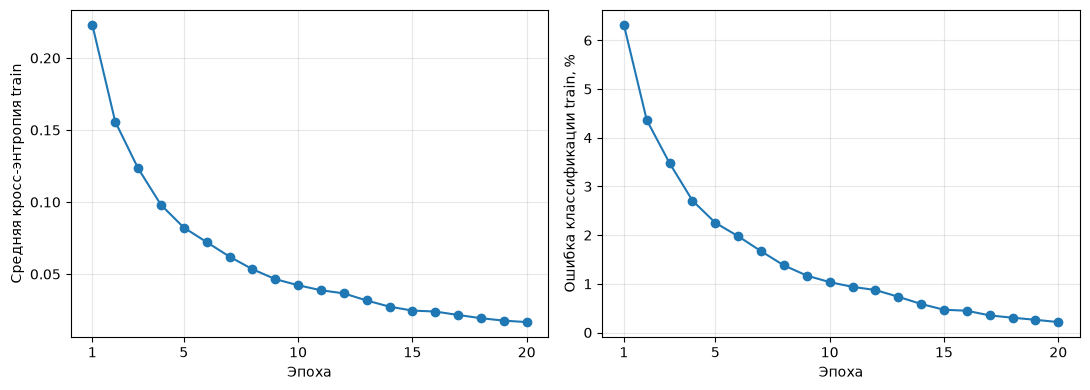

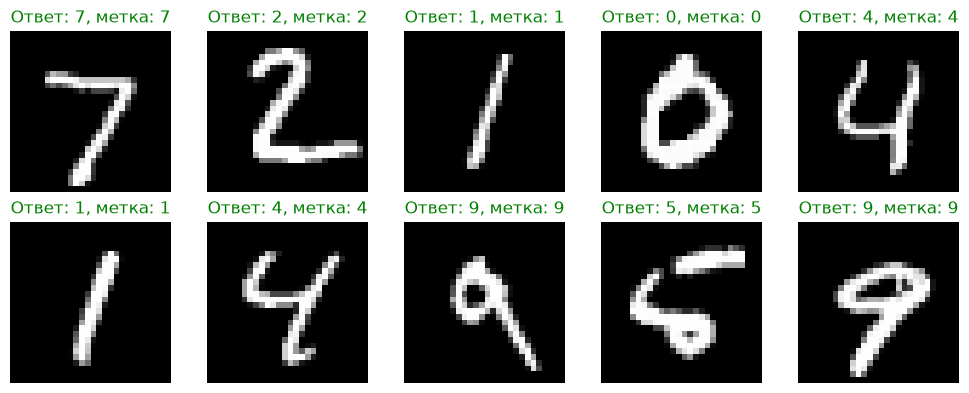

In [9]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, history["loss"], marker="o")
axes[0].set_ylabel("Средняя кросс-энтропия train")
axes[1].plot(epochs, 100 * np.array(history["error"]), marker="o")
axes[1].set_ylabel("Ошибка классификации train, %")
for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Показываем предсказания для первых тестовых изображений.
predictions = forward(X_test[:10], parameters)[3].argmax(axis=1)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(test_images[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Ответ: {predictions[i]}, метка: {y_test[i]}",
                 color="green" if predictions[i] == y_test[i] else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()